<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 5, 4)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 5, 3)           │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_dense (Dense)            │ (None, 5, 2)           │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32 (128.00 B)

 Trainable params: 32 (128.00 B)

 Non-trainable params: 0 (0.00 B)


Extracted Weight Shapes:
W_xh: (4, 3), W_hh: (3, 3), b_h: (3,)
W_hy: (3, 2), b_y: (2,)

=== Manual vs Keras Verification ===
t=1 ('speech   ') | Manual h_1: [-0.809  -0.5828  0.7704] | Keras h_1: [-0.809  -0.5828  0.7704]
t=2 ('analytics') | Manual h_2: [-0.9864 -0.3438  0.4346] | Keras h_2: [-0.9864 -0.3438  0.4346]
t=3 ('tracks   ') | Manual h_3: [-0.3756 -0.0552 -0.7933] | Keras h_3: [-0.3756 -0.0552 -0.7933]
t=4 ('spoken   ') | Manual h_4: [ 0.9987 -0.4904 -0.9918] | Keras h_4: [ 0.9987 -0.4904 -0.9918]
t=5 ('context  ') | Manual h_5: [ 0.9526 -0.0556  0.1146] | Keras h_5: [ 0.9526 -0.0556  0.1146]

Max Abs Difference (Hidden States): 1.19e-07 -> MATCH
Max Abs Difference (Outputs)      : 1.19e-07 -> MATCH



/tmp/ipykernel_873/3903590077.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


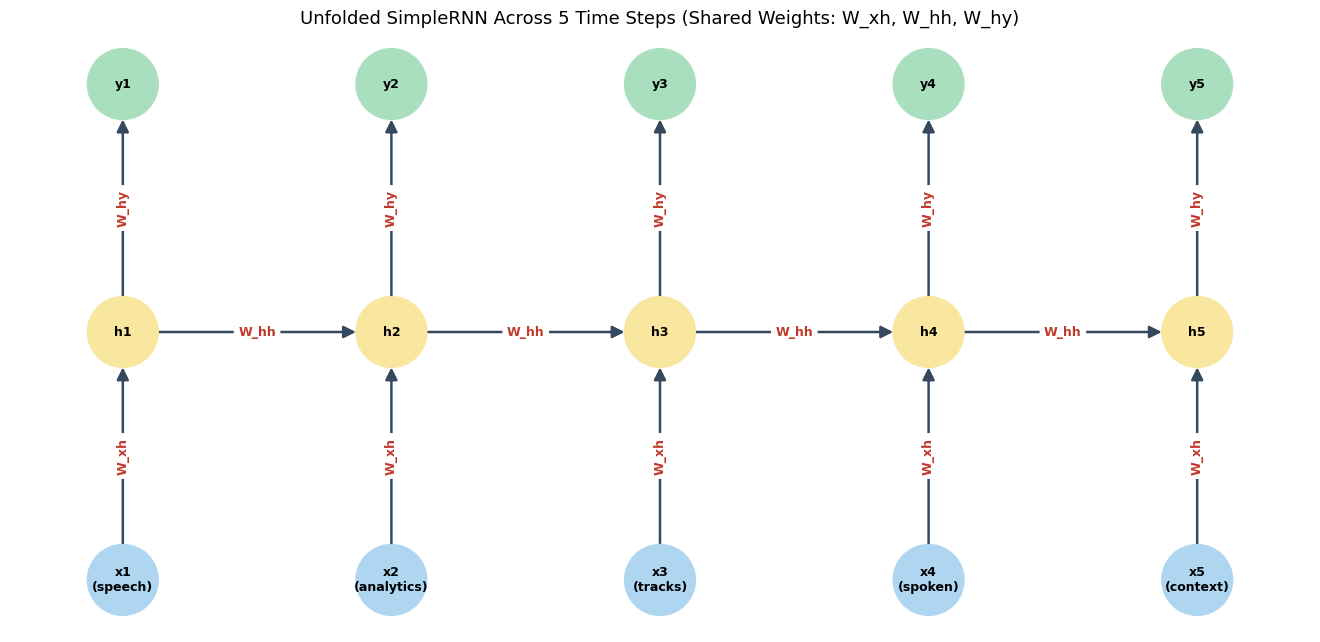

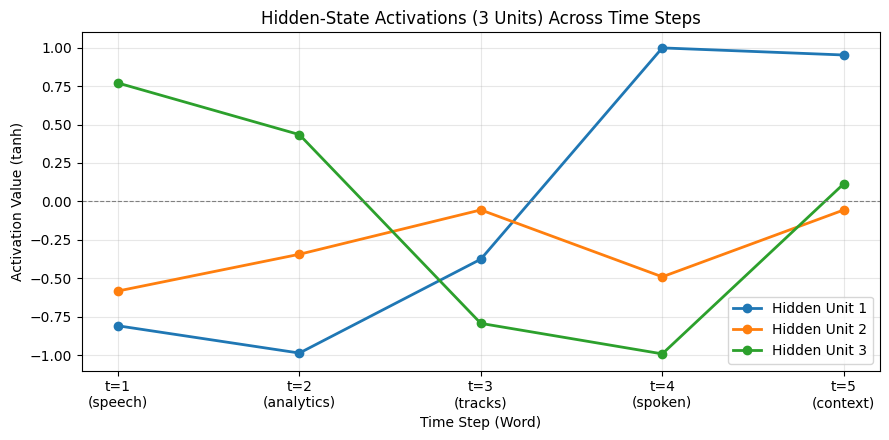

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Setup: 5-Word Input Sentence (4-D Embeddings)
# ==========================================
words = ["speech", "analytics", "tracks", "spoken", "context"]
T = len(words)        # 5 time steps
input_dim = 4         # Feature size per word
hidden_units = 3      # 3-unit hidden state
output_dim = 2        # Output vector size per time step

# Shape: (batch=1, time_steps=5, input_dim=4)
X_seq = np.random.randn(1, T, input_dim).astype(np.float32)

# ==========================================
# Task 1: Build SimpleRNN in Keras & Extract Weights
# ==========================================
inputs = keras.Input(shape=(T, input_dim))
rnn_layer = layers.SimpleRNN(hidden_units, activation="tanh", return_sequences=True, name="simple_rnn")
dense_layer = layers.Dense(output_dim, activation="linear", name="output_dense")

h_seq = rnn_layer(inputs)
y_seq = dense_layer(h_seq)

model = keras.Model(inputs=inputs, outputs=[h_seq, y_seq])
model.summary()

# Extract weights: W_xh, W_hh, b_h (from SimpleRNN) and W_hy, b_y (from Dense)
W_xh, W_hh, b_h = rnn_layer.get_weights()
W_hy, b_y = dense_layer.get_weights()

print(f"\nExtracted Weight Shapes:")
print(f"W_xh: {W_xh.shape}, W_hh: {W_hh.shape}, b_h: {b_h.shape}")
print(f"W_hy: {W_hy.shape}, b_y: {b_y.shape}\n")

# ==========================================
# Task 2: Manual Hidden-State Computation vs Keras
# ==========================================
keras_h, keras_y = model.predict(X_seq, verbose=0)
keras_h = keras_h[0]  # shape: (5, 3)
keras_y = keras_y[0]  # shape: (5, 2)

manual_h = np.zeros((T, hidden_units), dtype=np.float32)
manual_y = np.zeros((T, output_dim), dtype=np.float32)
h_prev = np.zeros((hidden_units,), dtype=np.float32)

for t in range(T):
    x_t = X_seq[0, t]
    h_t = np.tanh(x_t @ W_xh + h_prev @ W_hh + b_h)
    y_t = h_t @ W_hy + b_y
    manual_h[t] = h_t
    manual_y[t] = y_t
    h_prev = h_t

max_diff_h = np.max(np.abs(manual_h - keras_h))
max_diff_y = np.max(np.abs(manual_y - keras_y))

print("=== Manual vs Keras Verification ===")
for t, word in enumerate(words):
    print(f"t={t+1} ('{word:9s}') | Manual h_{t+1}: {np.round(manual_h[t], 4)} | Keras h_{t+1}: {np.round(keras_h[t], 4)}")

print(f"\nMax Abs Difference (Hidden States): {max_diff_h:.2e} -> {'MATCH' if np.allclose(manual_h, keras_h, atol=1e-6) else 'MISMATCH'}")
print(f"Max Abs Difference (Outputs)      : {max_diff_y:.2e} -> {'MATCH' if np.allclose(manual_y, keras_y, atol=1e-6) else 'MISMATCH'}\n")

# ==========================================
# Task 3 & 4: Draw Unfolded RNN Graph with NetworkX
# ==========================================
G = nx.DiGraph()
pos = {}
node_colors = []
edge_labels = {}

for t in range(1, T + 1):
    x_node = f"x{t}\n({words[t-1]})"
    h_node = f"h{t}"
    y_node = f"y{t}"

    G.add_nodes_from([x_node, h_node, y_node])
    pos[x_node] = (t * 2, 0)
    pos[h_node] = (t * 2, 1.5)
    pos[y_node] = (t * 2, 3.0)

    # Input -> Hidden (W_xh)
    G.add_edge(x_node, h_node)
    edge_labels[(x_node, h_node)] = "W_xh"

    # Hidden -> Output (W_hy)
    G.add_edge(h_node, y_node)
    edge_labels[(h_node, y_node)] = "W_hy"

    # Recurrent Hidden -> Next Hidden (W_hh)
    if t > 1:
        prev_h = f"h{t-1}"
        G.add_edge(prev_h, h_node)
        edge_labels[(prev_h, h_node)] = "W_hh"

for node in G.nodes():
    if node.startswith("x"):
        node_colors.append("#AED6F1")  # Light blue for inputs
    elif node.startswith("h"):
        node_colors.append("#F9E79F")  # Light yellow for hidden states
    else:
        node_colors.append("#A9DFBF")  # Light green for outputs

plt.figure(figsize=(13, 6))
nx.draw(
    G, pos,
    with_labels=True,
    node_color=node_colors,
    node_size=2600,
    font_size=9,
    font_weight="bold",
    arrows=True,
    arrowsize=18,
    edge_color="#34495E",
    width=1.8
)
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_color="#C0392B",
    font_size=9,
    font_weight="bold",
    label_pos=0.5
)
plt.title("Unfolded SimpleRNN Across 5 Time Steps (Shared Weights: W_xh, W_hh, W_hy)", fontsize=13)
plt.axis("off")
plt.tight_layout()
plt.show()

# ==========================================
# Task 5: Plot Hidden-State Values Across Time Steps
# ==========================================
time_steps = np.arange(1, T + 1)
plt.figure(figsize=(9, 4.5))
for u in range(hidden_units):
    plt.plot(time_steps, manual_h[:, u], marker="o", linewidth=2, label=f"Hidden Unit {u+1}")

plt.xticks(time_steps, [f"t={t}\n({words[t-1]})" for t in time_steps])
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.title("Hidden-State Activations (3 Units) Across Time Steps")
plt.xlabel("Time Step (Word)")
plt.ylabel("Activation Value (tanh)")
plt.ylim(-1.1, 1.1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()